In [44]:
import torch
from torch import nn
import math
import matplotlib.pyplot as plt
from torch.utils import data
torch.manual_seed(42)

In [45]:
#  y = 5 + 1.2x - 3.4x²/2! + 5.6x³/3!
def data_maker(w):
    x=torch.randn(200,1)
    powers=torch.arange(20).reshape(1,-1)
    x=x**powers
    factor=torch.tensor(
        [math.factorial(i) for i in range(20)],
        dtype=torch.float32
    )
    x/=factor
    y=torch.matmul(x,w)
    y+=torch.normal(size=y.size(),mean=0,std=0.1)
    
    return x,y


In [46]:
true_w=torch.zeros(20).reshape(20,1)
true_w[:4,:]=torch.tensor([5.0,1.2,-3.4,5.6]).reshape(4,1)

features,labels=data_maker(true_w)
train_features=features[:100]
train_labels=labels[:100]
test_features=features[100:]
test_labels=labels[100:]

In [47]:
def init(m):
    if type(m)==nn.Linear:
        nn.init.normal_(m.weight,mean=0,std=0.1)

In [48]:
def data_loader(data_array,batch_size,shuffle1):
    dataset=data.TensorDataset(*data_array)
    return data.DataLoader(dataset,batch_size,shuffle=shuffle1)

In [49]:
def train_set(train_features,train_labels,test_features,test_labels,lr1=0.01,epoch1=400):
    batch_size=10
    train_iter=data_loader((train_features,train_labels),batch_size,True)
    test_iter=data_loader((test_features,test_labels),batch_size,False)
    net=nn.Linear(train_features.size(1),1,bias=False)
    #net.apply(init)
    loss=nn.MSELoss()
    trainer=torch.optim.SGD(net.parameters(),lr=lr1)

    epoch=epoch1
    train_losses = []
    test_losses = []
    for i in range(epoch):
        train_loss_sum=0.0
        train_count=0
        test_loss_sum=0.0
        test_count=0
        net.train()
        for x,y in train_iter:
            trainer.zero_grad()
            l=loss(net(x),y)
            
            l.backward()
            trainer.step()
        #print(f'epoch={i+1},loss={train_loss_sum/train_count:5f}')
        #train_losses.append(train_loss_sum/train_count)
        net.eval()
        with torch.no_grad():
            for x,y in test_iter:
                l=loss(net(x),y)
                test_loss_sum+=l.item()*y.size(0)
                test_count+=y.size(0)
            
            #print(f'epoch={i+1},testloss={test_loss_sum/test_count:5f}')
            test_losses.append(test_loss_sum/test_count)
            for x,y in train_iter:
                l=loss(net(x),y)
                train_loss_sum+=l.item()*y.size(0)
                train_count+=y.size(0)
            train_losses.append(train_loss_sum/train_count)
        
    plt.plot(range(1,epoch+1),train_losses,label="Train")
    plt.plot(range(1,epoch+1),test_losses,label='Test')
    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()
    plt.show()
    print(net.weight.data)
   # print(net.bias.data)
            

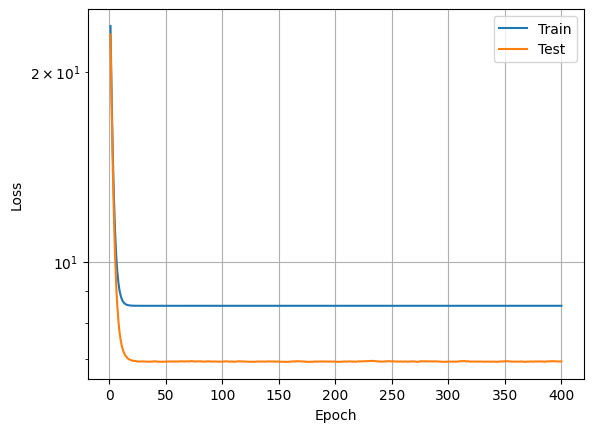

tensor([[3.1721, 3.5468]])


In [50]:
train_set(train_features[:,:2],train_labels,test_features[:,:2],test_labels)

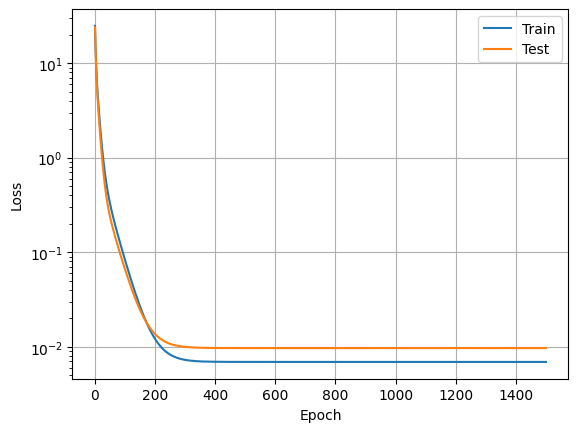

tensor([[ 5.0163,  1.2148, -3.4096,  5.5802]])


In [53]:
train_set(train_features[:,:4],train_labels,test_features[:,:4],test_labels,epoch1=1500)

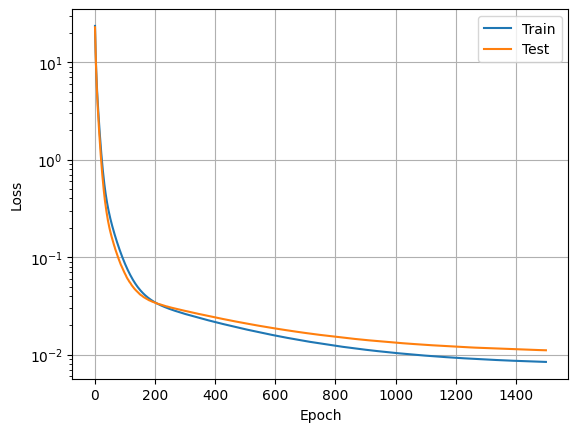

tensor([[ 4.9960,  1.2791, -3.3183,  5.2166, -0.2460,  1.1339,  0.2795, -0.0569,
         -0.0549, -0.0111, -0.0966,  0.1058,  0.1954,  0.1210, -0.0472, -0.1756,
         -0.1846, -0.0535, -0.0704, -0.1696]])


In [52]:
train_set(train_features[:,:],train_labels,test_features[:,:],test_labels,epoch1=1500)